# Анализ продаж Olist

Учебный портфолио-проект Junior Data Analyst на открытых анонимизированных данных бразильской торговой площадки Olist.

**Период анализа:** январь 2017 — август 2018.  
**Выручка:** сумма стоимости товаров в доставленных заказах без доставки.  
**Источник:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), лицензия CC BY-NC-SA 4.0.

Цель — проверить качество данных, собрать аналитическую витрину, рассчитать основные показатели и сформулировать выводы, которые непосредственно следуют из расчётов.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.analysis import (
    build_quality_report,
    build_summary_tables,
    calculate_metrics,
    load_raw_data,
    prepare_sales,
    save_figures,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 1. Загрузка и первичная проверка данных

In [2]:
raw = load_raw_data(ROOT / "data" / "raw")

raw_overview = pd.DataFrame([
    {
        "table": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "exact_duplicates": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
    }
    for name, frame in raw.items()
])
raw_overview

,table,rows,columns,exact_duplicates,missing_cells
0,customers,99441,5,0,0
1,orders,99441,8,0,4908
2,order_items,112650,7,0,0
3,products,32951,9,0,2448
4,category_translation,71,2,0,0
5,payments,103886,5,0,0


Пропуски в исходных таблицах не заменяются произвольными значениями. Для анализа продаж нужны дата покупки, статус заказа, покупатель, товар и цена. Недостающие переводы категорий сохраняются как `unknown`.

## 2. Очистка и объединение таблиц

In [3]:
sales, quality_stats = prepare_sales(raw)
quality_report = build_quality_report(quality_stats)

print(f"Строк в аналитической витрине: {len(sales):,}")
print(f"Уникальных заказов: {sales['order_id'].nunique():,}")
quality_report

Строк в аналитической витрине: 109,880
Уникальных заказов: 96,211


,check,row_count,treatment
0,Exact duplicate source rows,0,Removed before joins
1,Negative price or freight rows,0,Excluded as logically invalid
2,Orders not marked delivered,2963,Excluded from realized sales
3,Delivered orders outside 2017-01 to 2018-08,267,Excluded to keep complete comparable months
4,Item rows without translated product category,1557,Retained and labeled unknown
5,Item rows without mapped macro-region,0,Retained and labeled Unknown
6,Item prices above IQR threshold (BRL 275.57),8130,Flagged and retained; high prices can be valid...


Для сопоставимости месяцев используются доставленные заказы с 1 января 2017 года по 31 августа 2018 года. Дорогие товары, определённые правилом IQR, отмечены как выбросы, но не удалены: высокая цена сама по себе не доказывает ошибку.

## 3. Основные показатели

In [4]:
metrics = calculate_metrics(sales)
metrics_table = pd.DataFrame([
    ("Товарная выручка, BRL", metrics["total_revenue_brl"]),
    ("Доставленные заказы", metrics["orders"]),
    ("Проданные товарные позиции", metrics["items"]),
    ("Средний чек, BRL", metrics["average_order_value_brl"]),
    ("Уникальные покупатели", metrics["unique_customers"]),
    ("Повторные покупатели", metrics["repeat_customers"]),
    ("Доля повторных покупателей, %", metrics["repeat_customer_rate_pct"]),
], columns=["Показатель", "Значение"])
metrics_table

,Показатель,Значение
0,"Товарная выручка, BRL","13,181,027.13"
1,Доставленные заказы,"96,211.00"
2,Проданные товарные позиции,"109,880.00"
3,"Средний чек, BRL",137.00
4,Уникальные покупатели,"93,104.00"
5,Повторные покупатели,"2,789.00"
6,"Доля повторных покупателей, %",3.00


## 4. Динамика продаж по месяцам

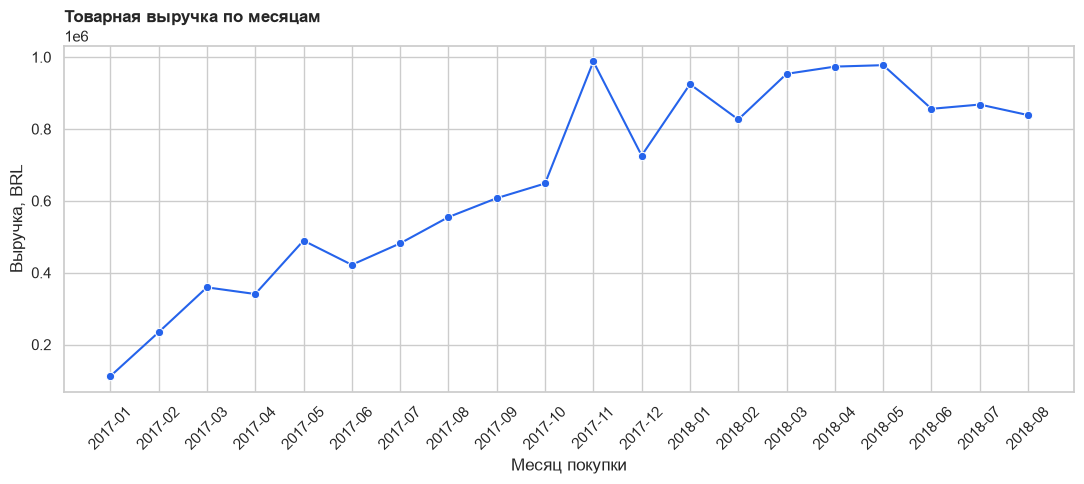

,purchase_month,revenue_brl,orders,items,average_order_value_brl
12,2018-01,"924,645.00",7069,8037,130.80
13,2018-02,"826,437.13",6555,7518,126.08
14,2018-03,"953,356.25",7003,8017,136.14
15,2018-04,"973,534.09",6798,7827,143.21
16,2018-05,"977,544.69",6749,7810,144.84
17,2018-06,"856,077.86",6099,7010,140.36
18,2018-07,"867,953.46",6159,6963,140.92
19,2018-08,"838,576.64",6351,7142,132.04


In [5]:
tables = build_summary_tables(sales)
monthly = tables["monthly_sales"].copy()

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly, x="purchase_month", y="revenue_brl", marker="o", color="#2563EB", ax=ax)
ax.set_title("Товарная выручка по месяцам", loc="left", weight="bold")
ax.set_xlabel("Месяц покупки")
ax.set_ylabel("Выручка, BRL")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

monthly.tail(8)

## 5. Категории товаров

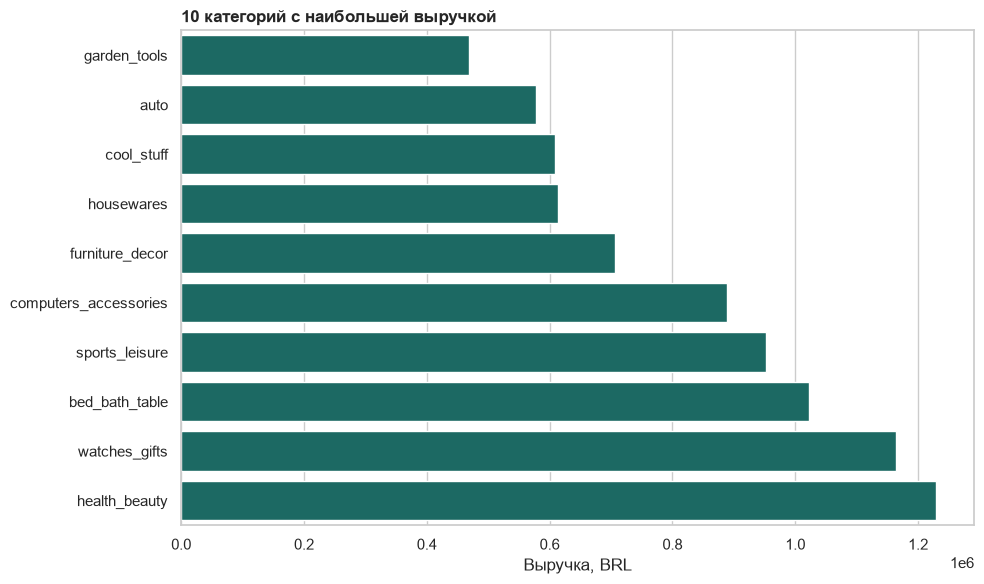

,product_category,revenue_brl,orders,items,revenue_share_pct
43,health_beauty,"1,229,557.50",8610,9422,9.33
71,watches_gifts,"1,163,465.91",5491,5855,8.83
7,bed_bath_table,"1,022,955.77",9267,10945,7.76
65,sports_leisure,"952,840.40",7513,8414,7.23
15,computers_accessories,"888,055.59",6518,7632,6.74
39,furniture_decor,"706,237.17",6258,8095,5.36
49,housewares,"614,341.62",5734,6783,4.66
20,cool_stuff,"609,158.00",3552,3711,4.62
5,auto,"577,838.39",3802,4132,4.38
42,garden_tools,"469,135.40",3443,4263,3.56


In [6]:
top_categories = tables["category_sales"].head(10).copy()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_categories.sort_values("revenue_brl"),
    x="revenue_brl",
    y="product_category",
    color="#0F766E",
    ax=ax,
)
ax.set_title("10 категорий с наибольшей выручкой", loc="left", weight="bold")
ax.set_xlabel("Выручка, BRL")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

top_categories

## 6. География продаж

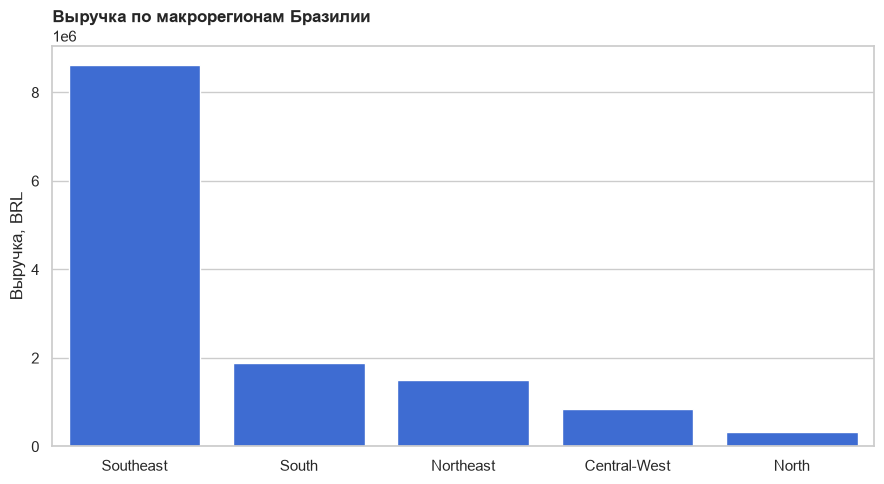

,customer_region,revenue_brl,orders,customers,revenue_share_pct
4,Southeast,"8,623,011.52",66027,63831,65.42
3,South,"1,895,195.99",13768,13339,14.38
2,Northeast,"1,491,911.33",9015,8784,11.32
0,Central-West,"844,960.64",5610,5436,6.41
1,North,"325,947.65",1791,1737,2.47


In [7]:
regions = tables["region_sales"].copy()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=regions, x="customer_region", y="revenue_brl", color="#2563EB", ax=ax)
ax.set_title("Выручка по макрорегионам Бразилии", loc="left", weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Выручка, BRL")
plt.tight_layout()
plt.show()

regions

## 7. Наиболее продаваемые товары

In [8]:
tables["top_products"].head(10)

,product_id,product_category,revenue_brl,orders,items_sold
21530,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,"37,104.30",425,520
8399,422879e10f46682990de24d770e7f83d,garden_tools,"26,577.22",352,484
19212,99a4788cb24856965c36a24e339b6058,bed_bath_table,"42,049.66",456,477
7182,389d119b48cf3043d311335e499d9c6b,garden_tools,"21,336.79",309,390
6903,368c6c730842d78016ad823897a372db,garden_tools,"21,056.80",291,388
10548,53759a2ecddad2bb87a079a1f1519f73,garden_tools,"20,387.20",287,373
26324,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,"45,620.56",313,332
10575,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,"37,454.63",304,321
2727,154e7e31ebfa092203795c972e5804a6,health_beauty,"6,173.26",262,274
7852,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,"40,782.80",253,272


Названия товаров в датасете отсутствуют, поэтому рейтинг показывает анонимизированные `product_id` и соответствующие категории.

## 8. Выводы

1. За выбранный период 96 211 доставленных заказов сформировали 13,18 млн BRL товарной выручки. Средний чек составил 137 BRL.
2. Выручка за январь–август 2018 года была на 141,1% выше, чем за те же месяцы 2017 года. Это описывает динамику выборки, но само по себе не объясняет причины роста.
3. Максимальная месячная выручка зафиксирована в ноябре 2017 года — 987,8 тыс. BRL. После этого в декабре показатель снизился на 26,5%.
4. Пять крупнейших категорий обеспечили 39,9% выручки. Лидер — `health_beauty` с долей 9,3%.
5. На Southeast пришлось 65,4% выручки, а на North — 2,5%. Продажи существенно сконцентрированы географически.
6. Повторными покупателями были 2 789 из 93 104 уникальных клиентов, или 3,0%.
7. 8 130 товарных строк превышают верхнюю границу IQR по цене. Они сохранены, поскольку без дополнительной проверки нельзя считать дорогие покупки ошибочными.

## 9. Рекомендации

1. Проверить сценарии второй покупки: послепродажные коммуникации, персональные предложения и сроки повторного заказа. Низкая доля повторных клиентов делает удержание отдельной зоной анализа.
2. Планировать запасы и продвижение с учётом концентрации выручки в пяти ведущих категориях, но контролировать зависимость от них.
3. Провести отдельный анализ причин ноябрьского пика и декабрьского снижения перед сезонным планированием. Данные показывают изменение, но не подтверждают его причину.
4. Тестировать региональные предложения за пределами Southeast и оценивать не только выручку, но также стоимость доставки и маржинальность, которых в текущем расчёте нет.
5. До решений по дорогим товарам проверить выбросы по первичным записям, категории и продавцу. Автоматически удалять их не следует.

## Ограничения

- В датасете нет себестоимости, поэтому рассчитана товарная выручка, а не прибыль.
- Стоимость доставки не включена в выручку.
- Данные относятся к Бразилии и периоду 2016–2018 годов; выводы нельзя автоматически переносить на текущий рынок.
- Наблюдаемые связи не доказывают причинность.

In [9]:
# Сохраняем компактные таблицы и изображения, использованные в README.
save_figures(tables, ROOT / "images")
print("Анализ выполнен. Итоговые таблицы и графики сохранены.")

Анализ выполнен. Итоговые таблицы и графики сохранены.
